# Module 1: A basic RAG application with LangGraph

Before we can attack or defend an LLM application, we need an application.
In this notebook we build a small **RAG (Retrieval-Augmented Generation)** app for a made-up company, **Acme Cloud**.

Every later module in this course uses this app as its starting point and shows where one of the
**OWASP Top 10 risks for LLM applications** enters it.

**How the app works**

```
User question ──► retrieve (vector store) ──► build one prompt ──► LLM ──► answer
                                              • system prompt
                                              • retrieved passages
                                              • user message
```

What we will do:
1. Load the API key
2. Look at the fake company documents
3. Turn the documents into embeddings and store them in a vector store
4. Build a LangGraph graph with two steps: `retrieve` and `generate`
5. Ask questions
6. See the same app running on the web with Streamlit

## 1. Setup

Create a file named `.env` in the project folder (copy `.env.example`) and put your key in it:

```
OPENAI_API_KEY=sk-...
```

`load_dotenv()` reads that file. The key is never written inside the notebook.

In [1]:
import os
from dotenv import load_dotenv

load_dotenv()

assert os.getenv("OPENAI_API_KEY"), "OPENAI_API_KEY is missing. Add it to the .env file."

CHAT_MODEL = os.getenv("OPENAI_MODEL", "gpt-4o-mini")
EMBEDDING_MODEL = os.getenv("OPENAI_EMBEDDING_MODEL", "text-embedding-3-small")
print("Chat model:     ", CHAT_MODEL)
print("Embedding model:", EMBEDDING_MODEL)

Chat model:      gpt-4o-mini
Embedding model: text-embedding-3-small


## 2. The fake knowledge base

The documents live in `fake_docs.py`. All of them are invented, so when the model answers we can tell
exactly which document the answer came from.

In [2]:
from fake_docs import DOCUMENTS

for d in DOCUMENTS:
    print(f"[{d['id']}] {d['title']}")
    print("   ", d["text"])
    print()

[hr-001] Leave policy
    Acme Cloud employees get 20 days of paid leave per year. Unused leave of up to 5 days can be carried over to the next year. Leave requests must be submitted in the HR portal at least 7 days in advance.

[hr-002] Remote work policy
    Employees may work remotely up to 3 days per week. Tuesdays and Thursdays are office days for all teams. Remote work from another country needs written approval from a manager.

[it-001] Password policy
    Passwords must be at least 14 characters long and must be changed every 180 days. Multi-factor authentication (MFA) is required for every company account. Never share your password with anyone, including the IT team.

[product-001] Pricing plans
    Acme Cloud has three plans. Starter costs $10 per month and includes 50 GB of storage. Pro costs $25 per month and includes 500 GB of storage. Enterprise has custom pricing and unlimited storage.

[product-002] Refund policy
    Customers can request a full refund within 30 days of

LangChain works with `Document` objects: the text goes in `page_content`, and anything extra
(id, title, source) goes in `metadata`.

In [3]:
from langchain_core.documents import Document

documents = [
    Document(page_content=d["text"], metadata={"id": d["id"], "title": d["title"]})
    for d in DOCUMENTS
]
documents[0]

Document(metadata={'id': 'hr-001', 'title': 'Leave policy'}, page_content='Acme Cloud employees get 20 days of paid leave per year. Unused leave of up to 5 days can be carried over to the next year. Leave requests must be submitted in the HR portal at least 7 days in advance.')

## 3. Embeddings and the vector store

An **embedding** turns text into a list of numbers. Texts with similar meaning get similar numbers.
The **vector store** keeps one embedding per document, and finds the documents closest to a question.

We use `InMemoryVectorStore` because it needs no database. It lives in Python memory only.

In [4]:
from langchain_openai import OpenAIEmbeddings
from langchain_core.vectorstores import InMemoryVectorStore

embeddings = OpenAIEmbeddings(model=EMBEDDING_MODEL)

vector = embeddings.embed_query("How many leave days do I get?")
print("One embedding has", len(vector), "numbers. First five:", [round(x, 4) for x in vector[:5]])

vector_store = InMemoryVectorStore(embeddings)
vector_store.add_documents(documents)
print("Documents stored:", len(documents))

One embedding has 1536 numbers. First five: [-0.0258, 0.0194, 0.069, 0.0136, 0.0097]
Documents stored: 6


Let's test retrieval on its own, before any LLM is involved. The score is the similarity (higher means closer).

In [5]:
results = vector_store.similarity_search_with_score("How much does the Pro plan cost?", k=2)
for doc, score in results:
    print(f"{score:.3f}  {doc.metadata['title']}: {doc.page_content[:70]}...")

0.556  Pricing plans: Acme Cloud has three plans. Starter costs $10 per month and includes 5...
0.350  Refund policy: Customers can request a full refund within 30 days of purchase. After ...


## 4. Build the RAG graph with LangGraph

LangGraph describes an application as a **graph**:
- **State**: a dictionary that carries data between steps
- **Nodes**: Python functions. Each one reads the state and returns the fields it updates
- **Edges**: the order in which the nodes run

Our graph is the simplest possible one: `START → retrieve → generate → END`.

### 4.1 State

In [6]:
from typing import TypedDict

class RAGState(TypedDict):
    question: str             # what the user asked
    context: list[Document]   # passages found by the retriever
    answer: str               # the LLM's reply

### 4.2 The prompt

This is the "application builds one prompt" box from the course diagram.
The system prompt, the retrieved passages and the user message are combined into **one** input for the LLM.
Keep this in mind: in later modules, most attacks work by sneaking text into one of these three parts.

In [7]:
SYSTEM_PROMPT = (
    "You are the Acme Cloud help assistant. "
    "Answer the user's question using only the context below. "
    "If the answer is not in the context, say \"I don't know based on the company documents.\" "
    "Keep answers short."
)

def build_messages(question: str, context: list[Document]):
    passages = "\n\n".join(f"[{d.metadata['title']}]\n{d.page_content}" for d in context)
    return [
        ("system", f"{SYSTEM_PROMPT}\n\nContext:\n{passages}"),
        ("user", question),
    ]

### 4.3 Nodes

In [8]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model=CHAT_MODEL, temperature=0)
TOP_K = 2

def retrieve(state: RAGState) -> dict:
    docs = vector_store.similarity_search(state["question"], k=TOP_K)
    return {"context": docs}

def generate(state: RAGState) -> dict:
    messages = build_messages(state["question"], state["context"])
    response = llm.invoke(messages)
    return {"answer": response.content}

### 4.4 Connect the nodes and compile

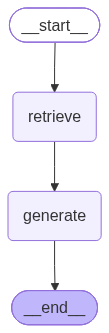

In [9]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(RAGState)
graph.add_node("retrieve", retrieve)
graph.add_node("generate", generate)
graph.add_edge(START, "retrieve")
graph.add_edge("retrieve", "generate")
graph.add_edge("generate", END)

rag_app = graph.compile()

# Draw the graph as a picture.
# draw_mermaid_png() sends the diagram text (only the node names) to the mermaid.ink website,
# so it needs internet access. If that fails, we print the Mermaid text instead
# (paste it into https://mermaid.live to see the picture).
from IPython.display import Image, display

try:
    display(Image(rag_app.get_graph().draw_mermaid_png()))
except Exception as error:
    print("Could not draw the image:", error)
    print(rag_app.get_graph().draw_mermaid())

## 5. Ask questions

In [10]:
def ask(question: str):
    result = rag_app.invoke({"question": question})
    print("Question:", question)
    print("Sources: ", [d.metadata["title"] for d in result["context"]])
    print("Answer:  ", result["answer"])
    print("-" * 80)
    return result

ask("How many days of paid leave do employees get?")
ask("Can I get a refund after 2 weeks?")
ask("How long must my password be?");

Question: How many days of paid leave do employees get?
Sources:  ['Leave policy', 'Remote work policy']
Answer:   Employees get 20 days of paid leave per year.
--------------------------------------------------------------------------------
Question: Can I get a refund after 2 weeks?
Sources:  ['Refund policy', 'Remote work policy']
Answer:   Yes, you can request a full refund within 30 days of purchase.
--------------------------------------------------------------------------------
Question: How long must my password be?
Sources:  ['Password policy', 'Leave policy']
Answer:   Your password must be at least 14 characters long.
--------------------------------------------------------------------------------


### A question the documents cannot answer

The system prompt tells the model to say "I don't know" when the answer is not in the context.
This is our first, very weak, safety rule. Later modules show how easily it can be bypassed.

In [11]:
ask("Who is the CEO of Acme Cloud?");

Question: Who is the CEO of Acme Cloud?
Sources:  ['Pricing plans', 'Customer support']
Answer:   I don't know based on the company documents.
--------------------------------------------------------------------------------


### Look inside the prompt

To understand the attacks later, it helps to see the exact prompt the LLM receives.

In [12]:
question = "What are the support hours?"
docs = vector_store.similarity_search(question, k=TOP_K)
for role, content in build_messages(question, docs):
    print(f"===== {role.upper()} =====")
    print(content)
    print()

===== SYSTEM =====
You are the Acme Cloud help assistant. Answer the user's question using only the context below. If the answer is not in the context, say "I don't know based on the company documents." Keep answers short.

Context:
[Customer support]
Support is available Monday to Friday, 9 AM to 6 PM IST. Customers can reach support by email at support@acmecloud.example or through live chat. Enterprise customers get 24/7 phone support.

[Remote work policy]
Employees may work remotely up to 3 days per week. Tuesdays and Thursdays are office days for all teams. Remote work from another country needs written approval from a manager.

===== USER =====
What are the support hours?



## 6. See it on the web (Streamlit)

The same code is saved in `rag_core.py` (graph) and `fake_docs.py` (data).
`app.py` is a small Streamlit page that uses them. From the project folder, run:

```
uv run streamlit run app.py
```

Then open http://localhost:8501 in your browser, ask a question, and you will see the answer together with the passages it was based on.

In [13]:
# Optional: check that rag_core.py gives the same result as the notebook
from rag_core import build_rag_graph

core_app = build_rag_graph()
core_app.invoke({"question": "How much does the Starter plan cost?"})["answer"]

'The Starter plan costs $10 per month.'

## 7. Where the security risks enter

Every arrow in this app is a place where something can go wrong. The next modules each take one of them:

| Where in the app | OWASP risk |
|---|---|
| User message | LLM01 Prompt injection |
| System prompt | LLM07 System prompt leakage |
| Documents / vector store | LLM01 Indirect prompt injection, LLM04 Data and model poisoning, LLM08 Vector and embedding weaknesses |
| The LLM itself | LLM03 Supply chain, LLM10 Unbounded consumption |
| The reply | LLM09 Misinformation, LLM02 Sensitive information disclosure |
| Reply sent to a user or another system | LLM05 Improper output handling |
| Tools and actions | LLM06 Excessive agency |

**Next:** each module imports `build_rag_graph` from `rag_core.py`, attacks the app, then adds a defense.